In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [4]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

학교 앞에서 찍은 낙엽 사진을 사용하였습니다.

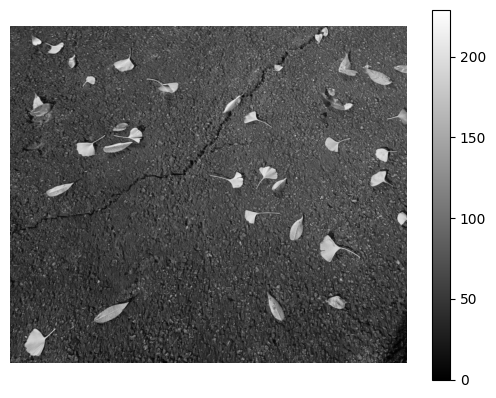

In [14]:
I = Image.open('leaf.jpeg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

처음 커널크기 7에서 시작하여, 9, 11까지도 1~5픽셀짜리의 아주 작은 흰 점도 object로 포착하였기 때문에 비록 낙엽의 꼬리 부분이 사라지고 전체적으로 경계가 옅어지는 문제가 생기지만 정확한 개수 count 및 가장 큰 object, 작은 object 판별을 위해 노이즈가 사라지는 최소값인 13 까지 커널의 크기를 키워 조정하였습니다.

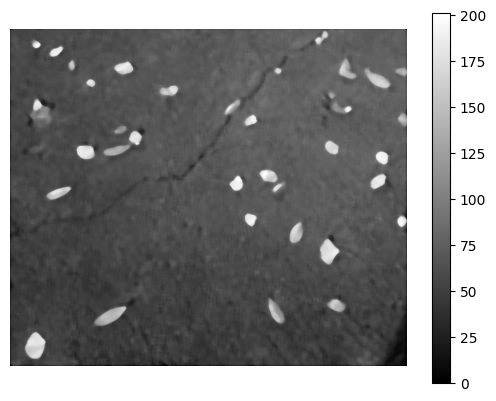

In [34]:
f_denoised = signal.medfilt2d(f,13)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

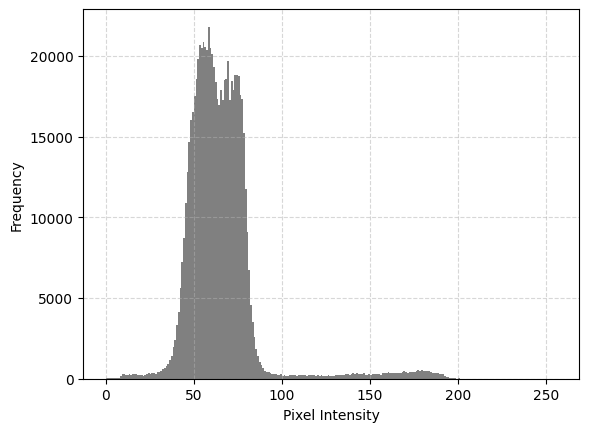

In [35]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

배경 색이 100 미만으로 몰려있기 때문에 임계점을 무난하게 100으로 정했습니다.

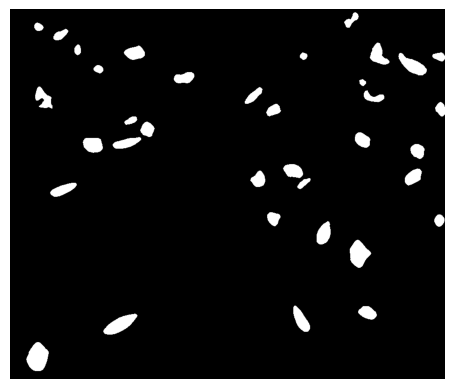

In [36]:
th_val = 100
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

흰 점이 나오지 않고 무난하게 잘 된 것 같습니다.

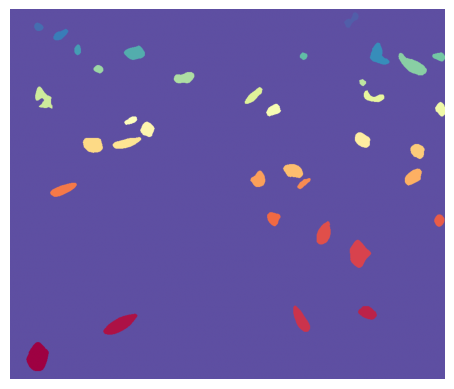

In [37]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [38]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 463
index: 2, number of pixels: 267
index: 3, number of pixels: 468
index: 4, number of pixels: 1073
index: 5, number of pixels: 252
index: 6, number of pixels: 968
index: 7, number of pixels: 191
index: 8, number of pixels: 375
index: 9, number of pixels: 1422
index: 10, number of pixels: 275
index: 11, number of pixels: 802
index: 12, number of pixels: 154
index: 13, number of pixels: 966
index: 14, number of pixels: 625
index: 15, number of pixels: 599
index: 16, number of pixels: 471
index: 17, number of pixels: 557
index: 18, number of pixels: 317
index: 19, number of pixels: 703
index: 20, number of pixels: 800
index: 21, number of pixels: 926
index: 22, number of pixels: 1120
index: 23, number of pixels: 730
index: 24, number of pixels: 951
index: 25, number of pixels: 890
index: 26, number of pixels: 761
index: 27, number of pixels: 330
index: 28, number of pixels: 949
index: 29, number of pixels: 611
index: 30, number of pixels: 435
index: 31, numbe

## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [39]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 31, # of pixels: 1746
the smallest component: index 11, # of pixels: 154


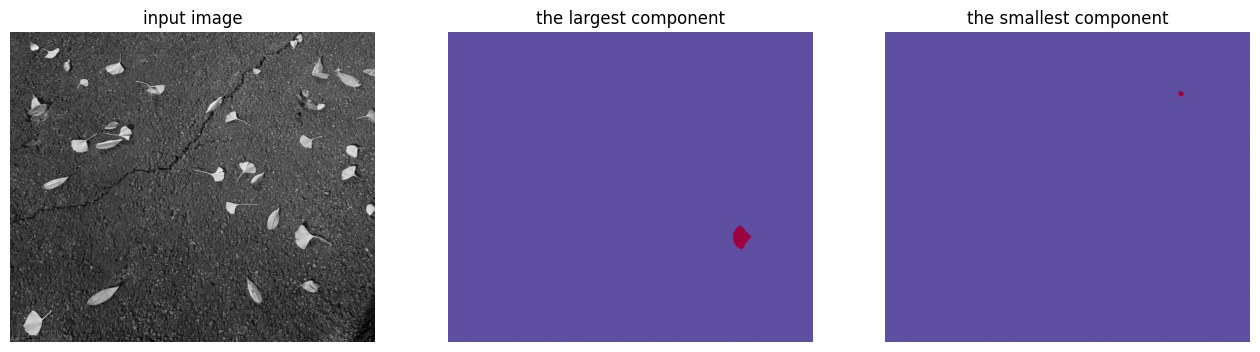

In [40]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()